# RNN - Recurrent Neural Network

In [1]:
# przetwarzanie danych
import numpy as np
import pandas as pd

# przekształcanie – normalizacja danych
from sklearn.preprocessing import MinMaxScaler

# wizualizacja
import matplotlib.pyplot as plt

# sieci neuronowe
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import SimpleRNN
from keras.layers import LSTM
from keras.layers import GRU

# ewaluacja modelu
from sklearn.metrics import mean_squared_error


In [2]:
dataset = pd.read_csv('airline-passengers.csv')
dataset['Month'] = pd.to_datetime(dataset['Month'])
dataset.set_index(['Month'], inplace=True)
dataset

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461


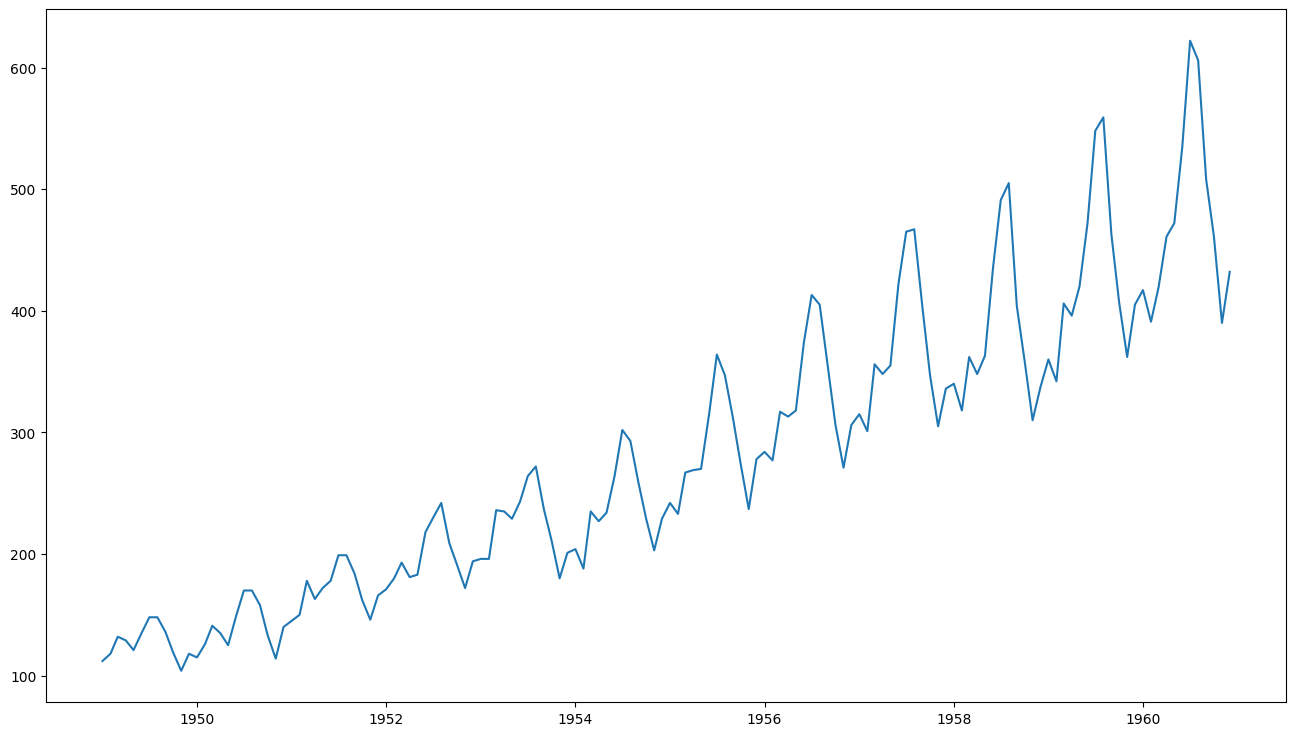

In [3]:
plt.figure(figsize=(16,9))
plt.plot(dataset['Passengers'])
plt.show()

In [4]:
train_size = int(len(dataset) * 0.70)
scaler = MinMaxScaler(feature_range=(0, 1))
look_back = 3
def create_dataset(df, train_size, lback=look_back, scaler_function=scaler):
    test_size = len(df) - train_size
    train, test = df[0:train_size,:].copy(), df[train_size:len(df),:].copy()
    train = scaler_function.fit_transform(train)
    test = scaler_function.transform(test)
    X_train, X_test, y_train, y_test = [], [], [], []

    # Tworzenie zbioru treninowego
    for i in range(len(train)-lback-1):
        a = train[i:(i+lback), 0]
        X_train.append(a)
        y_train.append(train[i + lback, 0])

    # Tworzenie zbioru testowego
    for i in range(len(test)-lback-1):
        a = test[i:(i+lback), 0]
        X_test.append(a)
        y_test.append(test[i + lback, 0])

    X_train, X_test = np.array(X_train), np.array(X_test)
    X_train, X_test = np.reshape(X_train, (X_train.shape[0], 1, X_train.shape[1])), np.reshape(X_test, (X_test.shape[0], 1, X_test.shape[1]))
    y_train, y_test = np.array(y_train), np.array(y_test)
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = create_dataset(df=np.array(dataset), train_size=train_size, lback=look_back)

In [12]:
X_train[:3]

array([[[0.02588997, 0.04530744, 0.09061489]],

       [[0.04530744, 0.09061489, 0.08090615]],

       [[0.09061489, 0.08090615, 0.05501618]]])

In [13]:
y_train[:3]

array([0.08090615, 0.05501618, 0.10032362])

## RNN

In [15]:

from tensorflow.keras import Input
model_rnn = Sequential()
model_rnn.add(Input(shape=(1, look_back)))
model_rnn.add(SimpleRNN(5))
model_rnn.add(Dense(1))
model_rnn.compile(loss='mean_squared_error', optimizer='adam')
model_rnn.fit(X_train, y_train, epochs=200, batch_size=1, verbose=1)

Epoch 1/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 599us/step - loss: 0.0113    
Epoch 2/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 499us/step - loss: 0.0077
Epoch 3/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - loss: 0.0065  
Epoch 4/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 482us/step - loss: 0.0060
Epoch 5/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 488us/step - loss: 0.0051  
Epoch 6/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 463us/step - loss: 0.0069
Epoch 7/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 476us/step - loss: 0.0070
Epoch 8/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 452us/step - loss: 0.0065
Epoch 9/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step - loss: 0.0051  
Epoch 10/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 489us/step - loss: 0.0060
Epoch 11/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 531us/step - loss: 0.0053  
Epoch 12/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 485us/step - loss: 0.0063
Epoch 13/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 487us/step - loss: 0.0065  
Epoch 14/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 488us/step - loss: 0.0091
Epoch 15/200
96/96 ━━━━━━━━━━

96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 483us/step - loss: 0.0066
Epoch 81/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 466us/step - loss: 0.0047
Epoch 82/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 495us/step - loss: 0.0051  
Epoch 83/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 488us/step - loss: 0.0062
Epoch 84/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 458us/step - loss: 0.0058
Epoch 85/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 474us/step - loss: 0.0043
Epoch 86/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 474us/step - loss: 0.0060
Epoch 87/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 458us/step - loss: 0.0053
Epoch 88/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 476us/step - loss: 0.0057  
Epoch 89/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 467us/step - loss: 0.0049  
Epoch 90/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 466us/step - loss: 0.0050
Epoch 91/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 493us/step - loss: 0.0054
Epoch 92/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 471us/step - loss: 0.0052  
Epoch 93/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 461us/step - loss: 0.0050  
Epoch 94/200
96/96 ━━━━━━━━━━━━━━━━━━

96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 501us/step - loss: 0.0061
Epoch 159/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - loss: 0.0044  
Epoch 160/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 470us/step - loss: 0.0058
Epoch 161/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 506us/step - loss: 0.0063
Epoch 162/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 475us/step - loss: 0.0049
Epoch 163/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 468us/step - loss: 0.0057
Epoch 164/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 470us/step - loss: 0.0055  
Epoch 165/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 465us/step - loss: 0.0056
Epoch 166/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step - loss: 0.0057
Epoch 167/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - loss: 0.0055
Epoch 168/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step - loss: 0.0055
Epoch 169/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step - loss: 0.0057
Epoch 170/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 451us/step - loss: 0.0050
Epoch 171/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 554us/step - loss: 0.0054
Epoch 172/200
96/96 ━━━━━━━━━━

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


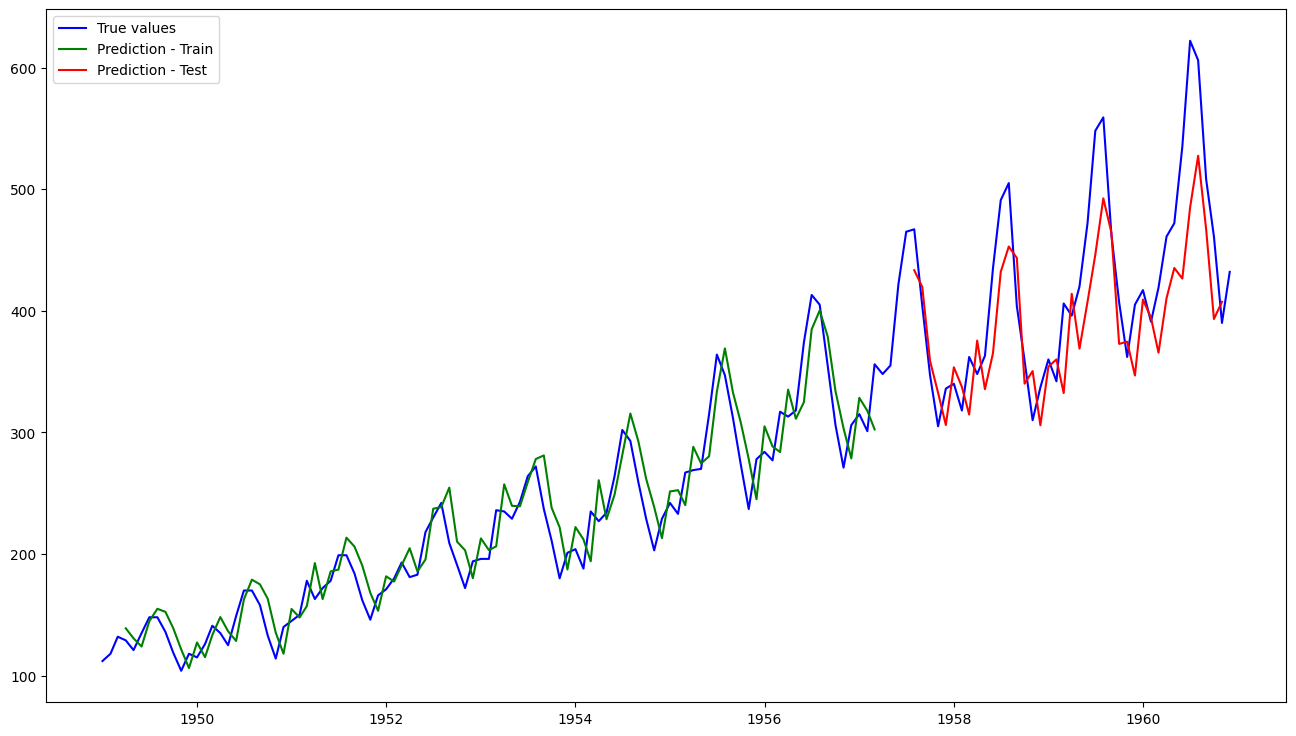


RMSE TEST: 51.395886113335955


In [16]:
def backtests(model, lback=look_back):

    # predykcja - train
    prediction_train = scaler.inverse_transform(model.predict(X_train))
    prediction_train = pd.Series(prediction_train.flatten(),
                                index=dataset.index[lback:len(prediction_train)+lback])

    # predykcja - test
    prediction_test = scaler.inverse_transform(model.predict(X_test))
    prediction_test = pd.Series(prediction_test.flatten(),
                                index=dataset.index[len(prediction_train)+(2*lback)+1:len(dataset)-1])

    # wizualizacja prognozy
    plt.figure(figsize=(16,9))
    plt.plot(dataset['Passengers'], color='blue', label='True values')
    plt.plot(prediction_train, color='green', label='Prediction - Train')
    plt.plot(prediction_test, color='red', label='Prediction - Test')
    plt.legend(loc='upper left')
    plt.show()

    # obliczenie RMSE
    rmse = mean_squared_error(dataset.loc[prediction_test.index, :], prediction_test) ** 0.5
    print(f'\nRMSE TEST: {rmse}')

backtests(model_rnn)

## LSTM

Epoch 1/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 667us/step - loss: 0.1953
Epoch 2/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 507us/step - loss: 0.1152
Epoch 3/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step - loss: 0.0596
Epoch 4/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 483us/step - loss: 0.0345  
Epoch 5/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 491us/step - loss: 0.0291
Epoch 6/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 510us/step - loss: 0.0275
Epoch 7/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 521us/step - loss: 0.0189
Epoch 8/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 524us/step - loss: 0.0144
Epoch 9/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 499us/step - loss: 0.0126
Epoch 10/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 528us/step - loss: 0.0176
Epoch 11/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 524us/step - loss: 0.0107
Epoch 12/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 527us/step - loss: 0.0116  
Epoch 13/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 497us/step - loss: 0.0068  
Epoch 14/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 522us/step - loss: 0.0087  
Epoch 15/200
96/96 ━━━━━━━━━━━━━━━━

96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 519us/step - loss: 0.0053
Epoch 81/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 502us/step - loss: 0.0053
Epoch 82/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 484us/step - loss: 0.0052
Epoch 83/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 497us/step - loss: 0.0048
Epoch 84/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step - loss: 0.0064
Epoch 85/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - loss: 0.0051  
Epoch 86/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 527us/step - loss: 0.0046  
Epoch 87/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 486us/step - loss: 0.0061
Epoch 88/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 488us/step - loss: 0.0060  
Epoch 89/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 638us/step - loss: 0.0058
Epoch 90/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 501us/step - loss: 0.0044  
Epoch 91/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - loss: 0.0048
Epoch 92/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 486us/step - loss: 0.0052
Epoch 93/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 486us/step - loss: 0.0050
Epoch 94/200
96/96 ━━━━━━━━━━━━━━━━━━━━

96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 537us/step - loss: 0.0051
Epoch 159/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 473us/step - loss: 0.0055  
Epoch 160/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 493us/step - loss: 0.0049
Epoch 161/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 505us/step - loss: 0.0044  
Epoch 162/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 496us/step - loss: 0.0048
Epoch 163/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 504us/step - loss: 0.0046  
Epoch 164/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 494us/step - loss: 0.0045
Epoch 165/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 515us/step - loss: 0.0058
Epoch 166/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 499us/step - loss: 0.0054
Epoch 167/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 579us/step - loss: 0.0045  
Epoch 168/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 496us/step - loss: 0.0059  
Epoch 169/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 478us/step - loss: 0.0058
Epoch 170/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 472us/step - loss: 0.0048
Epoch 171/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 488us/step - loss: 0.0044
Epoch 172/200
96/96 ━━━━

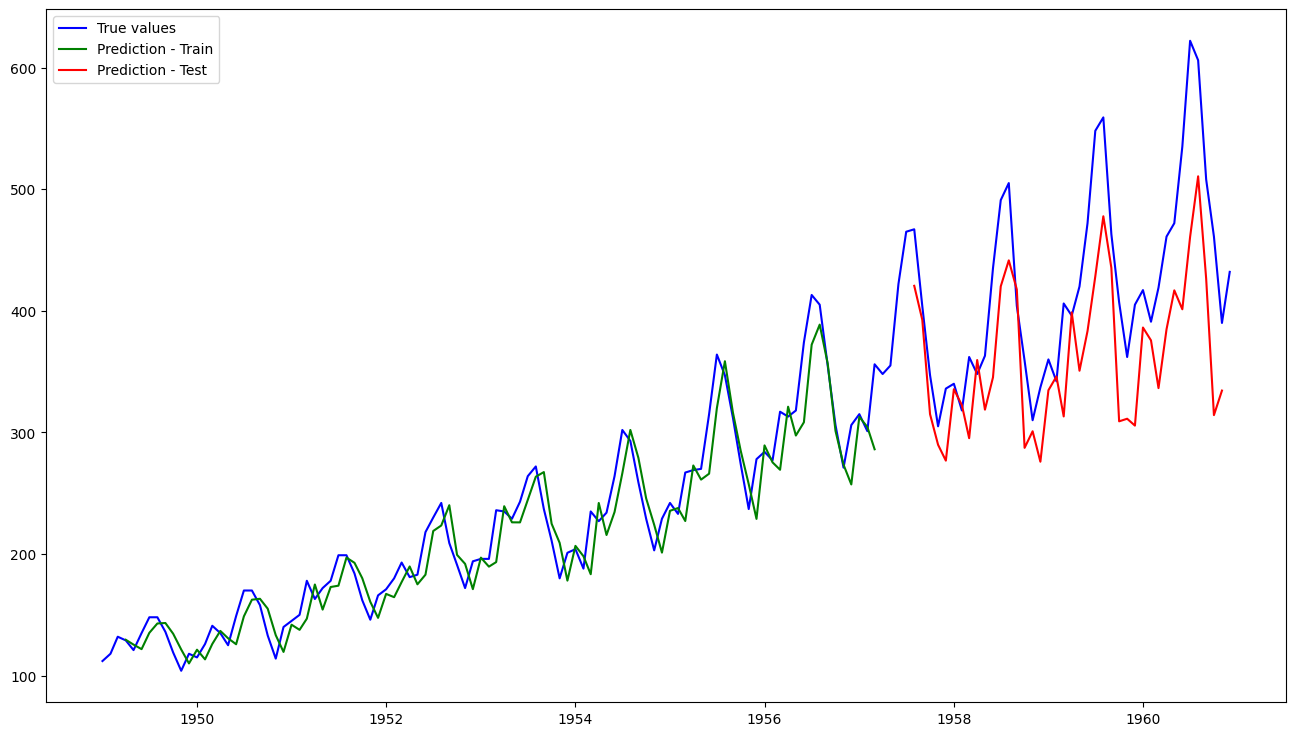


RMSE TEST: 71.8967324481353


In [17]:
model_lstm = Sequential()
model_lstm.add(Input(shape=(1, look_back)))
model_lstm.add(LSTM(5))
model_lstm.add(Dense(1))
model_lstm.compile(loss='mean_squared_error', optimizer='adam')
model_lstm.fit(X_train, y_train, epochs=200, batch_size=1, verbose=1)
backtests(model_lstm)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


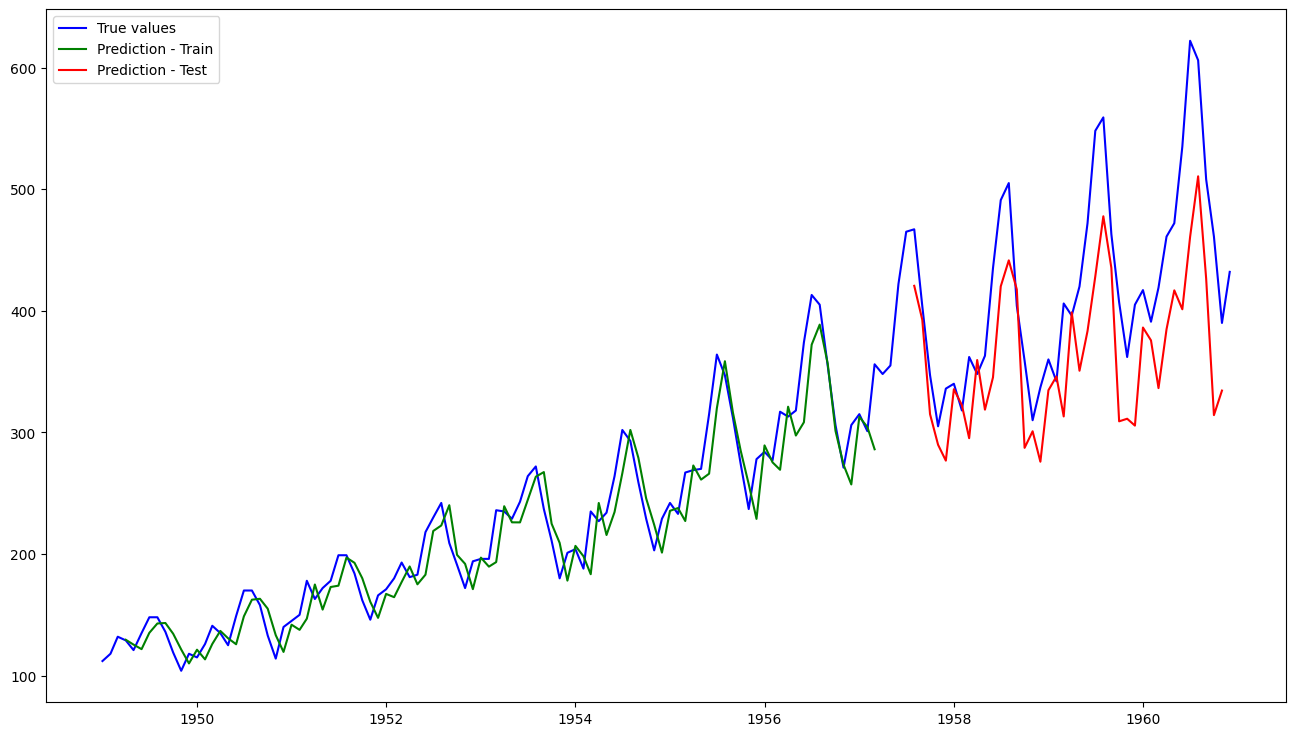


RMSE TEST: 71.8967324481353


In [18]:
backtests(model_lstm)

## GRU 

Epoch 1/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 634us/step - loss: 0.1658
Epoch 2/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 553us/step - loss: 0.0485
Epoch 3/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 558us/step - loss: 0.0256
Epoch 4/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 515us/step - loss: 0.0239  
Epoch 5/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 508us/step - loss: 0.0195
Epoch 6/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 523us/step - loss: 0.0157
Epoch 7/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 512us/step - loss: 0.0158
Epoch 8/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 495us/step - loss: 0.0147
Epoch 9/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 521us/step - loss: 0.0121
Epoch 10/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step - loss: 0.0122
Epoch 11/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 525us/step - loss: 0.0096
Epoch 12/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 484us/step - loss: 0.0122  
Epoch 13/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 484us/step - loss: 0.0095
Epoch 14/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 518us/step - loss: 0.0107
Epoch 15/200
96/96 ━━━━━━━━━━━━━━━━━━━━

96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 569us/step - loss: 0.0052
Epoch 81/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 501us/step - loss: 0.0054  
Epoch 82/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 485us/step - loss: 0.0054
Epoch 83/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 502us/step - loss: 0.0063
Epoch 84/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 490us/step - loss: 0.0054
Epoch 85/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step - loss: 0.0056
Epoch 86/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 501us/step - loss: 0.0049
Epoch 87/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 511us/step - loss: 0.0053
Epoch 88/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 477us/step - loss: 0.0048
Epoch 89/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 480us/step - loss: 0.0049  
Epoch 90/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 506us/step - loss: 0.0053
Epoch 91/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 504us/step - loss: 0.0048
Epoch 92/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 503us/step - loss: 0.0051  
Epoch 93/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 515us/step - loss: 0.0057  
Epoch 94/200
96/96 ━━━━━━━━━━━━━━━━━━━━

96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 525us/step - loss: 0.0065  
Epoch 159/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 582us/step - loss: 0.0046
Epoch 160/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 504us/step - loss: 0.0047
Epoch 161/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 487us/step - loss: 0.0050  
Epoch 162/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 498us/step - loss: 0.0064
Epoch 163/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 518us/step - loss: 0.0045
Epoch 164/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 516us/step - loss: 0.0064  
Epoch 165/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 502us/step - loss: 0.0055
Epoch 166/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 514us/step - loss: 0.0053
Epoch 167/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 507us/step - loss: 0.0049
Epoch 168/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 483us/step - loss: 0.0065
Epoch 169/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 488us/step - loss: 0.0073
Epoch 170/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 515us/step - loss: 0.0058
Epoch 171/200
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 501us/step - loss: 0.0051
Epoch 172/200
96/96 ━━━━━━━━

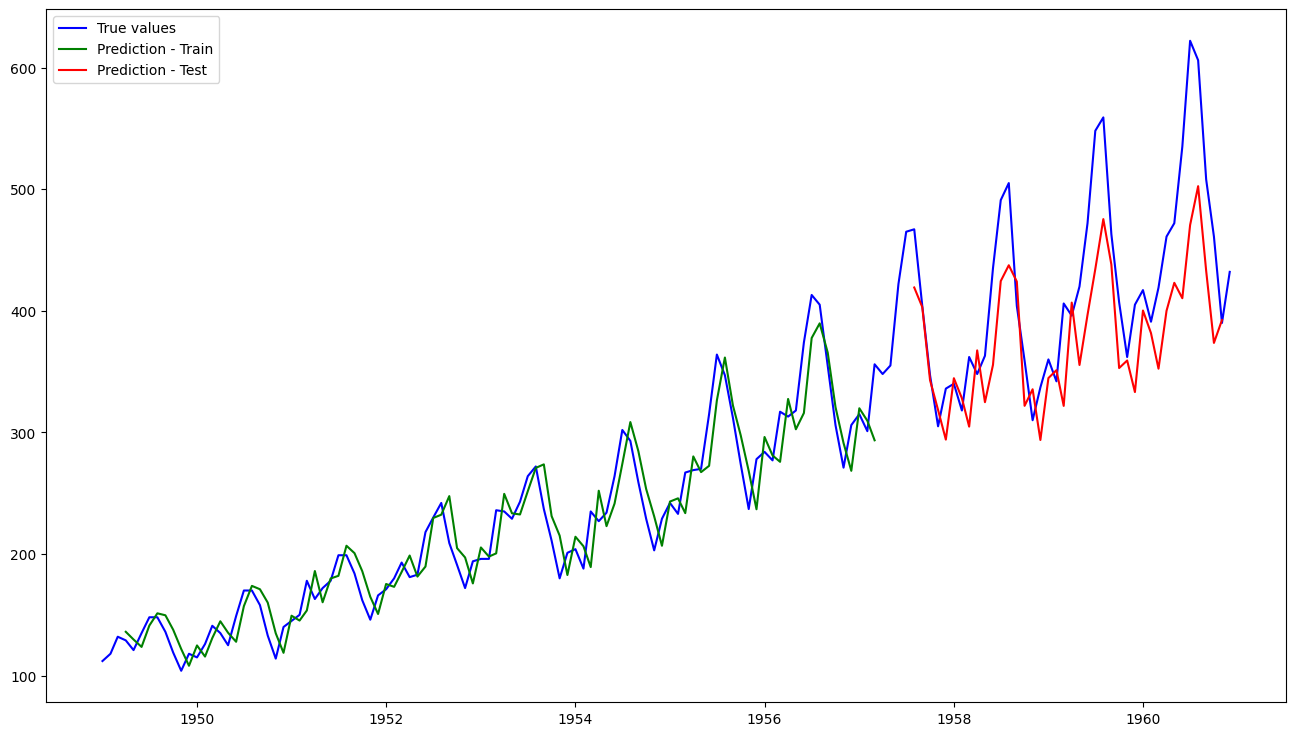


RMSE TEST: 60.94147022322935


In [19]:
model_gru = Sequential()
model_gru.add(Input(shape=(1, look_back)))
model_gru.add(GRU(5))
model_gru.add(Dense(1))
model_gru.compile(loss='mean_squared_error', optimizer='adam')
model_gru.fit(X_train, y_train, epochs=200, batch_size=1, verbose=1)
backtests(model_gru)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


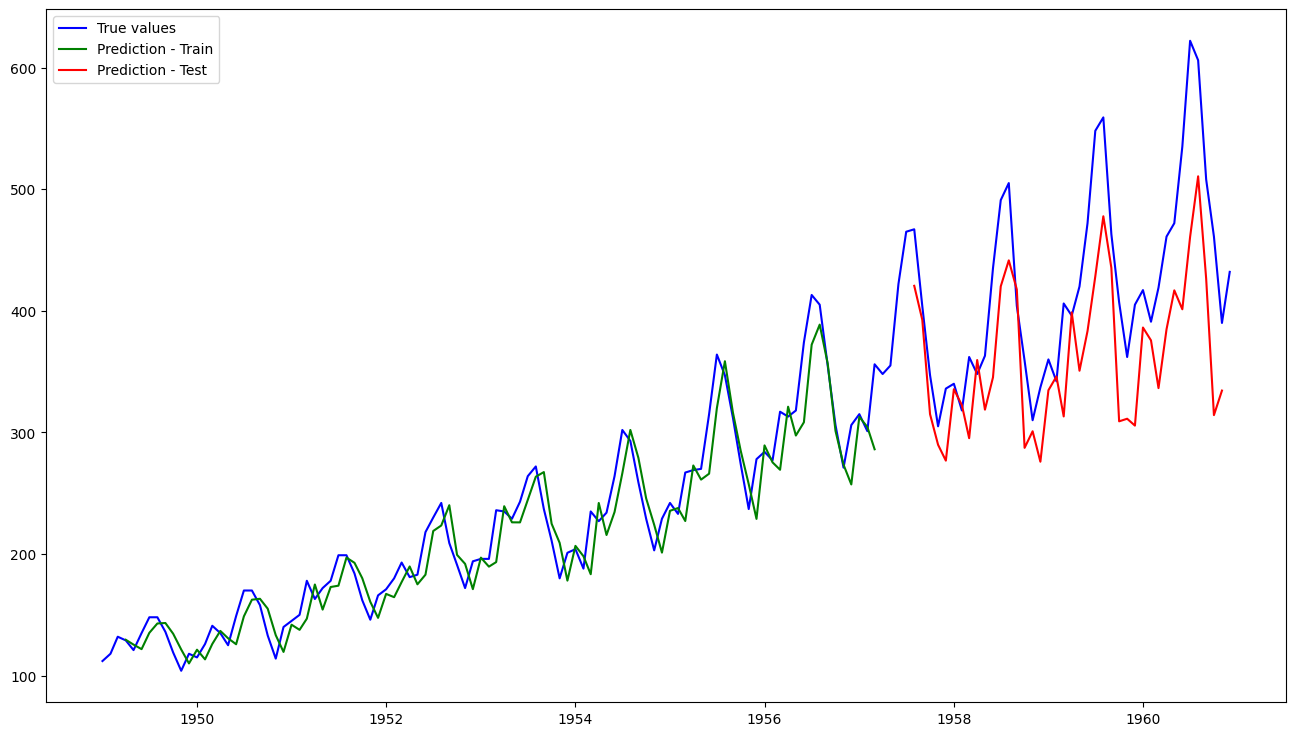


RMSE TEST: 71.8967324481353


In [20]:
backtests(model_lstm)